## E-Commerce Sales Analytics: SQL Analysis & Business Insights

### A. Database Schema

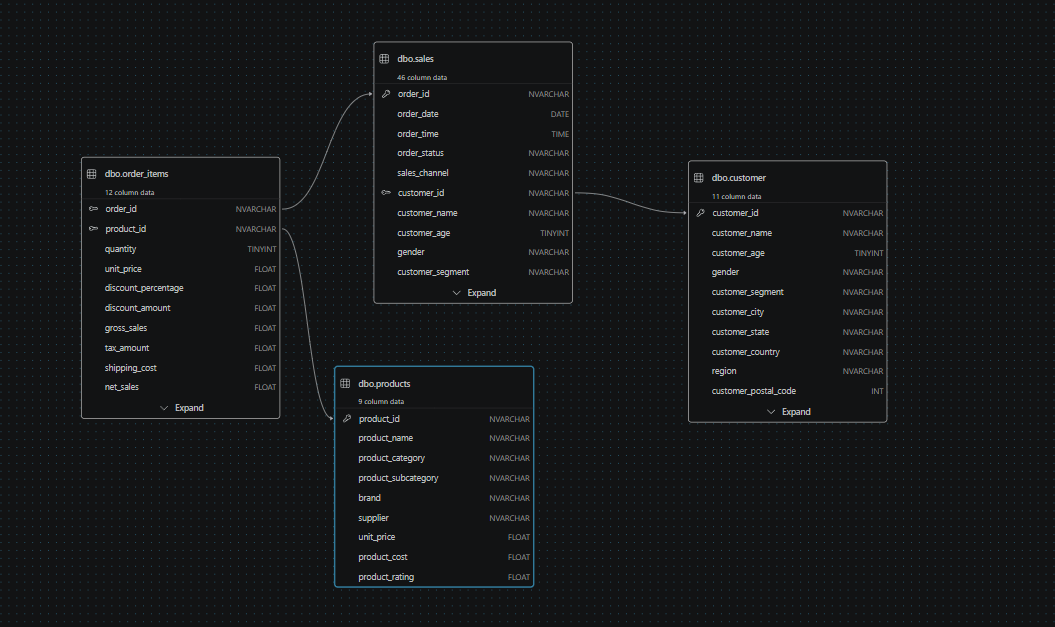

### B. Data Quality Investigation

In [ ]:
SELECT SUM(net_sales) as Revenue
FROM dbo.sales;

(1 row affected)

Revenue           
------------------
177134263.73624372
(1 row)

Total execution time: 00:00:00.109

In [ ]:
SELECT SUM(net_sales) as Revenue
FROM dbo.order_items;

(1 row affected)

Revenue          
-----------------
192398877.2921176
(1 row)

Total execution time: 00:00:00.132

An initial comparison of total revenue between the sales and order_items tables reveals a significant discrepancy of $15,264,613.56. 

In [ ]:
WITH order_quantity AS(
    SELECT order_id, SUM(quantity) as  item_quantity
    FROM dbo.order_items
    GROUP BY order_id
)
SELECT COUNT(*) AS Quantity_discrepancy_order FROM dbo.sales s
JOIN order_quantity o ON s.order_id = o.order_id
WHERE o.item_quantity <> s.quantity;


(1 row affected)

Total_discrepancy_order
-----------------------
11226                  
(1 row)

Total execution time: 00:00:01.497

In [10]:
WITH order_revenue AS(
    SELECT order_id, SUM(net_sales) as  item_revenue
    FROM dbo.order_items
    GROUP BY order_id
)
SELECT COUNT(*) AS Revenue_discrepancy_order FROM dbo.sales s
JOIN order_revenue o ON s.order_id = o.order_id
WHERE CONVERT(decimal(18,2),o.item_revenue)  <> CONVERT(decimal(18,2),s.net_sales);

(1 row affected)

Revenue_discrepancy_order
-------------------------
11226                    
(1 row)

Total execution time: 00:00:01.472

In [25]:
WITH all_discrepancy AS (
    SELECT order_id, SUM(net_sales) as  item_revenue, SUM(quantity) as  item_quantity
    FROM dbo.order_items
    GROUP BY order_id
)
SELECT COUNT(*) AS all_discrepancy_order, SUM(a.item_revenue-s.net_sales) AS total_revenue_difference, CAST(COUNT(*)*100.0/(SELECT COUNT(*) FROM dbo.sales)AS DECIMAL(10,2)) AS discrepancy_percentage FROM dbo.sales s
JOIN all_discrepancy a ON s.order_id = a.order_id
WHERE CONVERT(decimal(18,2),a.item_revenue)  <> CONVERT(decimal(18,2),s.net_sales) AND a.item_quantity <> s.quantity;

(1 row affected)

all_discrepancy_order | total_revenue_difference | discrepancy_percentage
----------------------+--------------------------+-----------------------
11226                 | 15264613.551429272       | 8.13                  
(1 row)

Total execution time: 00:00:01.868

##### Conclusion:
The investigation identified a revenue discrepancy of $15,264,613.56 between the sales and order_items tables. Further analysis revealed that 11,226 orders (8.13% of total orders) had both quantity and revenue discrepancies. Both discrepancies occurred in the exact same orders, suggesting a strong relationship between quantity and revenue inconsistencies. However, further investigation is required to determine the root cause.
Due to the identified revenue and quantity discrepancies, the sales table will be used as the primary revenue source for order-level and overall business analysis, while the order_items table will be used for product-level analysis. The original data will remain unchanged, and the identified discrepancies will be acknowledged as a limitation of the dataset.

### C. Table Inspection & Exploratory Data Analysis


#### 1. Currency Exchange

In [ ]:
CREATE VIEW dbo.vw_sales_usd AS
WITH currency_conversion AS (
    SELECT *,
        CASE currency
            WHEN 'USD' THEN 1.00        -- Apply currency exchange rates as of November 15, 2026
            WHEN 'AED' THEN 0.27
            WHEN 'AUD' THEN 0.68
            WHEN 'CAD' THEN 0.70
            WHEN 'EUR' THEN 1.10
            WHEN 'GBP' THEN 1.32
            WHEN 'INR' THEN 0.01
        END AS exchange_rate
    FROM dbo.sales
)
SELECT *,
    net_sales * exchange_rate AS usd_net,
    gross_sales * exchange_rate AS usd_gross,
    profit * exchange_rate AS usd_profit,
    discount_amount * exchange_rate AS usd_discount,
    shipping_cost * exchange_rate AS usd_shipping
FROM currency_conversion;

Commands completed successfully.

Total execution time: 00:00:00.095

In [4]:
CREATE VIEW dbo.vw_order_items_usd AS
SELECT
    oi.*,
    s.currency,
    s.exchange_rate,
    oi.net_sales * s.exchange_rate AS usd_net,
    oi.profit * s.exchange_rate AS usd_profit
FROM dbo.order_items AS oi
JOIN dbo.vw_sales_usd AS s
ON oi.order_id = s.order_id;

Commands completed successfully.

Total execution time: 00:00:00.083

#### 2. Sale, Revenue & Profitability Analytics

Question: How do monthly gross sales, net sales, and net profit change over time, and what are their growth rates compared to the same month in the previous year?

In [7]:
WITH 
monthly_metrics AS (
    SELECT DATEFROMPARTS(YEAR(order_date), MONTH(order_date), 1) AS sales_month,
        SUM(usd_net) AS net_sales,
        SUM(usd_gross) AS gross_sales,
        SUM(usd_profit) AS total_net_profit
    FROM dbo.vw_sales_usd
    GROUP BY DATEFROMPARTS(YEAR(order_date), MONTH(order_date), 1)
),
year_calculations AS (SELECT 
        curr.sales_month,
        curr.gross_sales,
        curr.net_sales,
        curr.total_net_profit,
        prev.gross_sales AS prev_year_gross_sales,
        prev.net_sales AS prev_year_net_sales,
        prev.total_net_profit AS prev_year_net_profit
    FROM monthly_metrics curr LEFT JOIN monthly_metrics prev
    ON prev.sales_month = DATEADD(YEAR, -1, curr.sales_month)
)
SELECT 
    FORMAT(sales_month, 'MMMM yyyy', 'en-US') AS sales_month,
    ROUND(gross_sales, 2) AS gross_sales,
    ROUND(net_sales, 2) AS net_sales,
    ROUND(total_net_profit, 2) AS total_net_profit,
    
    ROUND(((gross_sales - prev_year_gross_sales) / NULLIF(prev_year_gross_sales, 0)) * 100, 2) AS gross_sales_yoy_pct,
    ROUND(((net_sales - prev_year_net_sales) / NULLIF(prev_year_net_sales, 0)) * 100, 2) AS net_sales_yoy_pct,
    ROUND(((total_net_profit - prev_year_net_profit) / NULLIF(prev_year_net_profit, 0)) * 100, 2) AS net_profit_yoy_pct
FROM year_calculations
ORDER BY year_calculations.sales_month;


(60 rows affected)

sales_month    | gross_sales | net_sales  | total_net_profit | gross_sales_yoy_pct | net_sales_yoy_pct | net_profit_yoy_pct
---------------+-------------+------------+------------------+---------------------+-------------------+-------------------
January 2021   | 2224055.5   | 2258235.52 | 1077841.93       | NULL                | NULL              | NULL              
February 2021  | 1798683.83  | 1832424.07 | 869091.35        | NULL                | NULL              | NULL              
March 2021     | 2618918.11  | 2664940.73 | 1261303.65       | NULL                | NULL              | NULL              
April 2021     | 2373322.06  | 2416149.97 | 1159743.96       | NULL                | NULL              | NULL              
May 2021       | 2400621.36  | 2454465.43 | 1181054.43       | NULL                | NULL              | NULL              
June 2021      | 2571563.24  | 2618160.38 | 1254098.64       | NULL                | NULL              | NULL   

Key features:
* Gross sales exhibit a consistent seasonal pattern, with a moderate increase in June and July, followed by a significant surge in November and December.
* Despite the typical seasonal sales increases, June, July and December experienced negative year-over-year (YoY) growth rates in 2022, indicating weaker performance compared to the same months in 2021.
* Outside peak sales periods, monthly gross sales generally remained between **$2 million** and **$3 million** over the five-year period, indicating relatively stable baseline sales performance.
* February consistently recorded the lowest monthly gross sales, averaging approximately $1.9 million across the five-year period, suggesting a recurring slowdown following the year-end holiday season.

#### 3. Sales Performance Analysis by Sales and Marketing Channels


Question: How does sales performance vary across different sales channels?

In [27]:
SELECT
    sales_channel,
    SUM(quantity) AS total_items,
    COUNT(DISTINCT order_id) AS total_orders,
    ROUND(SUM(usd_net), 2) AS net_sales,
    ROUND(SUM(usd_profit), 2) AS profit,
    ROUND(SUM(usd_net) / COUNT(DISTINCT order_id), 2) AS AOV
FROM dbo.vw_sales_usd
WHERE payment_status = 'paid'
GROUP BY sales_channel;

(4 rows affected)

sales_channel | total_items | total_orders | net_sales   | profit      | AOV    
--------------+-------------+--------------+-------------+-------------+--------
Marketplace   | 89096       | 15524        | 19172758.17 | 7955028.36  | 1235.04
Mobile App    | 239783      | 41895        | 50931929.7  | 21201206.69 | 1215.7 
Social Media  | 60044       | 10546        | 12843495.66 | 5355141.76  | 1217.85
Website       | 206808      | 36285        | 44727395.55 | 18650194.67 | 1232.67
(4 rows)

Total execution time: 00:00:00.250

Question: How does sales performance vary across different marketing channels?

In [28]:
SELECT
    marketing_channel,
    SUM(quantity) AS total_items,
    COUNT(DISTINCT order_id) AS total_orders,
    ROUND(SUM(usd_net), 2) AS net_sales,
    ROUND(SUM(usd_profit), 2) AS profit,
    ROUND(SUM(usd_net) / COUNT(DISTINCT order_id), 2) AS AOV
FROM dbo.vw_sales_usd
WHERE payment_status = 'paid'
GROUP BY marketing_channel;

(10 rows affected)

marketing_channel | total_items | total_orders | net_sales   | profit      | AOV    
------------------+-------------+--------------+-------------+-------------+--------
Affiliate         | 30223       | 5184         | 6301391.36  | 2622345.25  | 1215.55
Direct            | 87499       | 15435        | 18765805.27 | 7848347     | 1215.8 
Email Marketing   | 48933       | 8451         | 10420309.17 | 4338908.35  | 1233.03
Facebook Ads      | 71884       | 12531        | 15342069.42 | 6397697.09  | 1224.33
Google Ads        | 88574       | 15593        | 19210409.38 | 7977771.9   | 1231.99
Instagram         | 59644       | 10425        | 12821918.86 | 5324944.19  | 1229.92
Organic Search    | 120006      | 21045        | 25718165.32 | 10687189.94 | 1222.06
Referral          | 47800       | 8376         | 10213927.84 | 4257565.41  | 1219.43
TikTok            | 23376       | 4103         | 5065822.39  | 2120583.01  | 1234.66
YouTube           | 17792       | 3107       

Key features:
* Mobile App and Website are the leading sales channels, each individually outperforming the combined sales performance of Marketplace and Social Media across all key sales metrics. This highlights customers' strong preference for direct shopping platforms.
* Organic Search, Google Ads, and Direct are the three leading marketing channels, collectively generating 296,079 items sold and approximately $63.69 million in revenue. This suggests that search engines and direct website visits play a major role in attracting customer attention and driving sales.

#### 4. Customer Analytics

Question: How do average Customer Lifetime Value (CLV), Customer Acquisition Cost (CAC), and the CLV-to-CAC ratio vary across customer segments and countries?

In [25]:
WITH customer_ltv AS (
    SELECT
        customer_id,
        MAX(customer_lifetime_value) AS ltv
    FROM dbo.vw_sales_usd
    GROUP BY customer_id
)
SELECT c.customer_segment, c.customer_country,
    ROUND(AVG(cu.ltv),2) AS ltv,
    ROUND(AVG(c.customer_acquisition_cost),2) AS cac,
    ROUND(AVG(cu.ltv)/AVG(c.customer_acquisition_cost),2) As ltv_to_cac
FROM dbo.customer c JOIN customer_ltv cu
ON c.customer_id = cu.customer_id
GROUP BY c.customer_segment,c.customer_country
ORDER BY c.customer_country,
CASE c.customer_segment
    WHEN 'VIP' THEN 1
    WHEN 'Premium' THEN 2
    WHEN 'Business' THEN 3
    WHEN 'Consumer' THEN 4
    ELSE 5
END;

(28 rows affected)

customer_segment | customer_country | ltv     | cac   | ltv_to_cac
-----------------+------------------+---------+-------+-----------
VIP              | Australia        | 7839.15 | 43.5  | 180.21    
Premium          | Australia        | 7519.36 | 43.27 | 173.76    
Business         | Australia        | 8136.23 | 42.78 | 190.2     
Consumer         | Australia        | 7790.3  | 42.73 | 182.32    
VIP              | Canada           | 8098.07 | 38.58 | 209.9     
Premium          | Canada           | 7772.79 | 42.17 | 184.33    
Business         | Canada           | 7493.27 | 47.09 | 159.14    
Consumer         | Canada           | 7946.48 | 42.8  | 185.67    
VIP              | Germany          | 8727.25 | 40.89 | 213.46    
Premium          | Germany          | 8286.28 | 42.41 | 195.4     
Business         | Germany          | 8709.02 | 41.65 | 209.12    
Consumer         | Germany          | 8517.44 | 42.44 | 200.69    
VIP              | India            | 7921

Question: How does total revenue vary across different customer age groups?

In [35]:
WITH age_range AS (
    SELECT
        customer_id,
        usd_net,
        CASE
            WHEN customer_age <= 18 THEN '0-18'
            WHEN customer_age <= 34 THEN '19-34'
            WHEN customer_age <= 54 THEN '35-54'
            WHEN customer_age <= 64 THEN '55-64'
            WHEN customer_age >= 65 THEN '65+'
            ELSE 'Unknown'
        END AS age_group
    FROM dbo.vw_sales_usd
)
SELECT
    age_group,
    ROUND(SUM(usd_net), 2) AS total_revenue
FROM age_range
GROUP BY age_group
ORDER BY age_group;


(5 rows affected)

age_group | total_revenue
----------+--------------
0-18      | 2912523.75   
19-34     | 48333243.68  
35-54     | 59942216.39  
55-64     | 29830441.92  
65+       | 29676178.94  
(5 rows)

Total execution time: 00:00:00.146

Question: How do the top 20 customers contribute to overall sales performance in terms of order count, average order value (AOV), total profit, and customer lifetime value (CLV)?

In [9]:
WITH customer_ltv AS (
    SELECT
        customer_id, count(distinct order_id) AS total_order,
        ROUND(SUM(net_sales),2) as total_revenue,
        ROUND(SUM(profit),2) as total_profit,
        ROUND(SUM(usd_net) / COUNT(DISTINCT order_id), 2) as AOV,
        ROUND(MAX(customer_lifetime_value),2) AS LTV
    FROM dbo.vw_sales_usd
    GROUP BY customer_id
)
SELECT TOP 20 DENSE_RANK() OVER (ORDER BY cu.total_revenue DESC) AS customer_rank, c.customer_id, c.customer_segment, cu.total_revenue, 
cu.total_profit, cu.AOV, cu.LTV
FROM dbo.customer c JOIN customer_ltv cu
ON c.customer_id = cu.customer_id
ORDER BY customer_rank;

(20 rows affected)

customer_rank | customer_id | customer_segment | total_revenue | total_profit | AOV     | LTV     
--------------+-------------+------------------+---------------+--------------+---------+---------
1             | CUST-012869 | Consumer         | 30268.44      | 11818.95     | 1412.53 | 30268.44
2             | CUST-002969 | Premium          | 30061.58      | 11703.8      | 18.79   | 30061.58
3             | CUST-017251 | Premium          | 29375.34      | 10563.05     | 1958.36 | 29375.34
4             | CUST-000802 | Consumer         | 28503.23      | 12782.04     | 3135.36 | 29157.92
5             | CUST-012608 | Premium          | 28172.12      | 13993.62     | 2383.79 | 28172.12
6             | CUST-017828 | Business         | 28092.99      | 12397.89     | 2006.64 | 28092.99
7             | CUST-006857 | Consumer         | 26835.08      | 9357.22      | 2683.51 | 27430.88
8             | CUST-017523 | Consumer         | 26776.65      | 12663.43     | 3272.7  |

Key Features:
* The LTV-to-CAC ratio ranges from 171.9x to 213.4x, with the United Kingdom and Germany recording the highest ratios. These two countries also consistently have the highest average Customer Lifetime Value (LTV) across all customer segments.
* Customers aged 19–54 account for approximately 62% of total revenue, generating $108.28 million. This highlights the importance of this age group to overall sales performance.
* The majority of the highest revenue-generating customers belong to the Consumer and Premium segments, indicating that these segments play a significant role in driving overall sales.

#### 5. Product

Question: Which products are the most popular by sales volume?

In [ ]:
SELECT TOP 20
    p.product_id,
    p.product_name,
    SUM(oi.quantity) AS total_units_sold,
    ROUND(SUM(oi.usd_net), 2) AS total_revenue_usd,
    ROUND(SUM(oi.usd_profit), 2) AS total_profit_usd
FROM dbo.vw_order_items_usd AS oi
JOIN dbo.products AS p
ON oi.product_id = p.product_id
GROUP BY p.product_id,
    p.product_name
ORDER BY total_units_sold DESC;

(20 rows affected)

product_id  | product_name                                                          | total_units_sold | total_revenue_usd | total_profit_usd
------------+-----------------------------------------------------------------------+------------------+-------------------+-----------------
PROD-000839 | Arm & Hammer Organized maximized software Grooming                    | 904              | 128310.53         | 52133.44        
PROD-000003 | LG Face-to-face client-driven support Smartphones                     | 865              | 218503.18         | 59879.57        
PROD-000694 | Goodyear Managed clear-thinking secured line Tools                    | 854              | 351402.79         | 193383.16       
PROD-000449 | Adidas Public-key homogeneous functionalities Team Sports             | 846              | 280775.79         | 133059.58       
PROD-000549 | HarperCollins Operative multi-tasking budgetary management Movies     | 844              | 14529.67          | 578

Question: Which products generate the most revenue?

In [13]:
SELECT TOP 20
    p.product_id,
    p.product_name,
    ROUND(SUM(oi.usd_net), 2) AS total_revenue_usd
FROM dbo.vw_order_items_usd AS oi
JOIN dbo.products AS p
ON oi.product_id = p.product_id
GROUP BY p.product_id,
    p.product_name
ORDER BY total_revenue_usd DESC;


(20 rows affected)

product_id  | product_name                                                    | total_revenue_usd
------------+-----------------------------------------------------------------+------------------
PROD-000062 | OnePlus Adaptive uniform success Gaming Consoles                | 925146.95        
PROD-000024 | Asus Re-engineered content-based strategy Tablets               | 892903.13        
PROD-000065 | Xiaomi Self-enabling exuding productivity Gaming Consoles       | 891779.75        
PROD-000074 | Asus Configurable upward-trending matrix TVs                    | 883396.13        
PROD-000051 | HP Versatile actuating budgetary management Smart Watches       | 871230.58        
PROD-000043 | OnePlus Streamlined modular infrastructure Smart Watches        | 864873.44        
PROD-000012 | LG Reverse-engineered even-keeled workforce Smartphones         | 855987.75        
PROD-000077 | OnePlus Switchable methodical neural-net TVs                    | 824208.9         


Question: Which product catergory generate the most profit?

In [ ]:
SELECT p.product_category,
    SUM(oi.quantity) AS total_units_sold,
    ROUND(SUM(oi.usd_net), 2) AS total_revenue_usd,
    ROUND(SUM(oi.usd_profit), 2) AS total_profit_usd
FROM dbo.vw_order_items_usd AS oi
JOIN dbo.products AS p
ON oi.product_id = p.product_id
GROUP BY p.product_category
ORDER BY total_units_sold DESC;

(15 rows affected)

product_category       | total_units_sold | total_revenue_usd | total_profit_usd
-----------------------+------------------+-------------------+-----------------
Sports & Outdoors      | 64752            | 15123897.92       | 6977413.8       
Books & Media          | 62305            | 2744284           | 1431271.9       
Health & Wellness      | 62054            | 8909214.12        | 4130309.66      
Beauty & Personal Care | 59765            | 4541287.05        | 2382730.57      
Automotive             | 58046            | 15885423.58       | 6284613.87      
Office Supplies        | 57631            | 8576915.53        | 4440234.66      
Home Appliances        | 56281            | 23949225.2        | 9957162.31      
Toys & Games           | 55788            | 5261161.29        | 2699848.59      
Electronics            | 55784            | 39575480.51       | 13651125.5      
Grocery                | 55607            | 2886502.74        | 1597578.22      
Baby & K

Question: Which brands generate the most revenue?

In [20]:
SELECT TOP 20 p.brand,
    ROUND(SUM(oi.usd_net), 2) AS total_revenue_usd
FROM dbo.vw_order_items_usd AS oi
JOIN dbo.products AS p
ON oi.product_id = p.product_id
GROUP BY p.brand
ORDER BY total_revenue_usd DESC;

(20 rows affected)

brand        | total_revenue_usd
-------------+------------------
Samsung      | 6623517.01       
LG           | 5940384.32       
OnePlus      | 4862872.09       
Asus         | 4660555.45       
HP           | 4384928.42       
David Yurman | 4293340.55       
Whirlpool    | 3930286.8        
Pandora      | 3654304.49       
Sony         | 3627535.51       
Dyson        | 3461053.67       
Mikimoto     | 3309024.89       
Xiaomi       | 3228604.4        
Apple        | 3044097.92       
Google       | 2873956.41       
Castrol      | 2817594.21       
Adidas       | 2713753.61       
Puma         | 2685278.06       
Tiffany      | 2648625.56       
Dell         | 2608609.64       
Bosch        | 2605881.5        
(20 rows)

Total execution time: 00:00:00.367

Question: How profitable are the top-selling products?

In [ ]:
WITH product_performance AS (
    SELECT
        p.product_id,
        p.product_name,
        SUM(oi.quantity) AS units_sold,
        SUM(oi.usd_net) AS total_revenue,
        SUM(oi.usd_profit) AS total_profit,
        SUM(oi.usd_profit) * 100.0 /
            NULLIF(SUM(oi.usd_net), 0) AS profit_margin_pct
    FROM dbo.vw_order_items_usd oi
    JOIN dbo.products p
    ON oi.product_id = p.product_id
    GROUP BY
        p.product_id,
        p.product_name
),
product_benchmarks AS (
    SELECT
        AVG(CAST(units_sold AS FLOAT)) AS avg_units_sold,
        AVG(profit_margin_pct) AS avg_profit_margin
    FROM product_performance
)
SELECT TOP 20
    p.product_id,
    p.product_name,
    p.units_sold,
    ROUND(p.total_revenue, 2) AS total_revenue,
    ROUND(p.total_profit, 2) AS total_profit,
    ROUND(p.profit_margin_pct, 2) AS profit_margin_pct
FROM product_performance p
CROSS JOIN product_benchmarks b
WHERE p.units_sold > b.avg_units_sold
AND p.profit_margin_pct < b.avg_profit_margin
ORDER BY p.units_sold DESC;

(20 rows affected)

product_id  | product_name                                                       | units_sold | total_revenue | total_profit | profit_margin_pct
------------+--------------------------------------------------------------------+------------+---------------+--------------+------------------
PROD-000839 | Arm & Hammer Organized maximized software Grooming                 | 904        | 128310.53     | 52133.44     | 40.63            
PROD-000003 | LG Face-to-face client-driven support Smartphones                  | 865        | 218503.18     | 59879.57     | 27.4             
PROD-000549 | HarperCollins Operative multi-tasking budgetary management Movies  | 844        | 14529.67      | 5783.08      | 39.8             
PROD-000928 | Evenflo Customizable content-based adapter Strollers               | 835        | 217855.61     | 71913.17     | 33.01            
PROD-000375 | Target Distributed encompassing circuit Lighting                   | 826        | 258757.86     

Question: How do product categories perform over time?

In [ ]:
WITH category_yearly AS (
    SELECT
        p.product_category,
        YEAR(s.order_date) AS sales_year,
        SUM(oi.quantity) AS units_sold,
        SUM(oi.usd_net) AS revenue,
        SUM(oi.usd_profit) AS profit
    FROM dbo.vw_order_items_usd AS oi
    JOIN dbo.products AS p
        ON oi.product_id = p.product_id
    JOIN dbo.sales AS s
        ON oi.order_id = s.order_id
    GROUP BY
        p.product_category,
        YEAR(s.order_date)
),
category_growth AS (
    SELECT *, LAG(revenue) OVER (PARTITION BY product_category ORDER BY sales_year) AS previous_year_revenue
    FROM category_yearly
),
category_performance AS ( SELECT product_category, sales_year, units_sold, revenue, profit, 
        profit * 100.0 / NULLIF(revenue, 0) AS profit_margin_pct,
        (revenue - previous_year_revenue) * 100.0 / NULLIF(previous_year_revenue, 0) AS yoy_growth_pct
    FROM category_growth
)
SELECT
    product_category,
    sales_year,
    units_sold,
    ROUND(revenue, 2) AS revenue,
    ROUND(profit, 2) AS profit,
    ROUND(profit_margin_pct, 2) AS profit_margin_pct,
    ROUND(yoy_growth_pct, 2) AS yoy_growth_pct
FROM category_performance
ORDER BY sales_year DESC, yoy_growth_pct DESC;

(75 rows affected)

product_category       | sales_year | units_sold | revenue    | profit     | profit_margin_pct | yoy_growth_pct
-----------------------+------------+------------+------------+------------+-------------------+---------------
Home & Kitchen         | 2025       | 10017      | 2165005.55 | 1034206.55 | 47.77             | 5.5           
Fashion                | 2025       | 9933       | 1454246.6  | 719282.55  | 49.46             | 3.68          
Electronics            | 2025       | 10990      | 7910103.19 | 2741905.52 | 34.66             | 2.45          
Automotive             | 2025       | 11826      | 3201501.65 | 1274044.24 | 39.8              | 2.12          
Books & Media          | 2025       | 12816      | 562996.47  | 293997.18  | 52.22             | 1.26          
Office Supplies        | 2025       | 11461      | 1726740.61 | 899082.33  | 52.07             | 0.69          
Health & Wellness      | 2025       | 12373      | 1797945.2  | 836921.61  | 46.55  

Key features:
* The best-selling product generated 904 units sold, while the highest-revenue product earned approximately $925K. These rankings highlight that high sales volume does not necessarily translate into high revenue.
* Electronics is the highest-performing product category, generating approximately **$39.58** million in revenue and **$13.65** million in profit, despite ranking ninth in total units sold.
* Most product categories experience both positive and negative YoY revenue growth, indicating inconsistent performance over time.In 2025, Home & Kitchen (+5.50%) and Fashion (+3.68%) recorded the strongest growth, while Home Appliances (-6.81%) and Sports & Outdoors (-4.84%) experienced notable declines.

#### 6. Pricing and Discount

Question: How do different discount levels affect sales performance?

In [18]:
WITH discount_groups AS(SELECT order_id, quantity,
 CASE
    WHEN ROUND((usd_discount/NULLIF(usd_gross, 0))*100,2) < 5 THEN '0-5%'
    WHEN ROUND((usd_discount/NULLIF(usd_gross, 0))*100,2) < 10 THEN '5-10%'
    WHEN ROUND((usd_discount/NULLIF(usd_gross, 0))*100,2) < 15 THEN '10-15%'
    WHEN ROUND((usd_discount/NULLIF(usd_gross, 0))*100,2) < 20 THEN '15-20%'
    ELSE '20%+'
    END AS discount_label
FROM dbo.vw_sales_usd
)
SELECT dg.discount_label, SUM(dg.quantity) AS Total_Units_Sold, COUNT(DISTINCT dg.order_id) AS Total_Orders,
CAST(SUM(dg.quantity) * 1.0 / NULLIF(COUNT(DISTINCT dg.order_id), 0) AS DECIMAL(10,2)) AS Avg_Units_per_Order
FROM discount_groups dg
GROUP BY dg.discount_label
ORDER BY CASE discount_label
        WHEN '0-5%' THEN 1
        WHEN '5-10%' THEN 2
        WHEN '10-15%' THEN 3
        WHEN '15-20%' THEN 4
        WHEN '20%+' THEN 5
    END;

(5 rows affected)

discount_label | Total_Units_Sold | Total_Orders | Avg_Units_per_Order
---------------+------------------+--------------+--------------------
0-5%           | 131537           | 28079        | 4.68               
5-10%          | 127031           | 24786        | 5.13               
10-15%         | 152405           | 28662        | 5.32               
15-20%         | 103966           | 20551        | 5.06               
20%+           | 260616           | 36038        | 7.23               
(5 rows)

Total execution time: 00:00:00.349

Question: How do different discount levels affect profit margins?

In [23]:
WITH discount_groups AS(SELECT order_id, quantity, profit_margin_percentage ,
 CASE
    WHEN ROUND((usd_discount/NULLIF(usd_gross, 0))*100,2) < 5 THEN '0-5%'
    WHEN ROUND((usd_discount/NULLIF(usd_gross, 0))*100,2) < 10 THEN '5-10%'
    WHEN ROUND((usd_discount/NULLIF(usd_gross, 0))*100,2) < 15 THEN '10-15%'
    WHEN ROUND((usd_discount/NULLIF(usd_gross, 0))*100,2) < 20 THEN '15-20%'
    ELSE '20%+'
    END AS discount_label
FROM dbo.vw_sales_usd
)
SELECT dg.discount_label, ROUND(AVG(profit_margin_percentage),2) AS profit_margin
FROM discount_groups dg
GROUP BY dg.discount_label
ORDER BY CASE discount_label
        WHEN '0-5%' THEN 1
        WHEN '5-10%' THEN 2
        WHEN '10-15%' THEN 3
        WHEN '15-20%' THEN 4
        WHEN '20%+' THEN 5
    END;

(5 rows affected)

discount_label | profit_margin
---------------+--------------
0-5%           | 53.54        
5-10%          | 50.44        
10-15%         | 47.9         
15-20%         | 44.94        
20%+           | 32.58        
(5 rows)

Total execution time: 00:00:00.348

Question: Which categories respond best to discounts?

In [40]:
WITH discount_groups AS (
    SELECT order_id, CASE
            WHEN usd_discount * 100.0 / usd_gross < 5 THEN '0-5%'
            WHEN usd_discount * 100.0 / usd_gross < 10 THEN '5-10%'
            WHEN usd_discount * 100.0 / usd_gross < 15 THEN '10-15%'
            WHEN usd_discount * 100.0 / usd_gross < 20 THEN '15-20%'
            ELSE '20%+'
        END AS discount_label
    FROM dbo.vw_sales_usd
)
SELECT p.product_category AS Category,
    dg.discount_label AS Discount_group,
    COUNT(DISTINCT oi.order_id) AS Total_Orders,
    SUM(oi.quantity) AS Units_Sold,
    CAST( SUM(oi.quantity) * 1.0 / COUNT(DISTINCT oi.order_id) AS DECIMAL(10,2)) AS Avg_Units_per_Order,
    CAST(SUM(oi.usd_net) AS DECIMAL(18,2)) AS Revenue,
    CAST(SUM(oi.usd_profit) AS DECIMAL(18,2)) AS Profit,
    CAST(SUM(oi.usd_profit) * 100.0 / SUM(oi.usd_net) AS DECIMAL(10,2)) AS Profit_Margin
FROM dbo.vw_order_items_usd oi JOIN dbo.products p
ON oi.product_id = p.product_id
JOIN discount_groups dg
ON oi.order_id = dg.order_id
GROUP BY p.product_category,dg.discount_label
ORDER BY p.product_category,
    CASE dg.discount_label
        WHEN '0-5%' THEN 1
        WHEN '5-10%' THEN 2
        WHEN '10-15%' THEN 3
        WHEN '15-20%' THEN 4
        WHEN '20%+' THEN 5
    END;

(75 rows affected)

Category               | Discount_group | Total_Orders | Units_Sold | Avg_Units_per_Order | Revenue     | Profit     | Profit_Margin
-----------------------+----------------+--------------+------------+---------------------+-------------+------------+--------------
Automotive             | 0-5%           | 4830         | 10153      | 2.10                | 3270531.04  | 1585128.58 | 48.47        
Automotive             | 5-10%          | 4626         | 9689       | 2.09                | 2947105.04  | 1334149.63 | 45.27        
Automotive             | 10-15%         | 5428         | 11146      | 2.05                | 3155070.75  | 1334753.49 | 42.31        
Automotive             | 15-20%         | 3571         | 7770       | 2.18                | 2170194.89  | 850046.20  | 39.17        
Automotive             | 20%+           | 6648         | 19288      | 2.90                | 4342521.86  | 1180535.97 | 27.19        
Baby & Kids            | 0-5%           | 4291   

Question: Which products receive the largest discounts?

In [ ]:
SELECT TOP 20 p.product_name, p.product_category, SUM(oi.quantity) AS Units_sold,
    CAST(AVG(oi.discount_percentage) * 100.0 AS DECIMAL(10,2) ) AS AVG_Discount_Percent,
    ROUND((oi.discount_amount * oi.exchange_rate),2) AS Total_discount,
    ROUND(SUM(oi.usd_net),2) AS Revenue
FROM dbo.vw_order_items_usd oi
JOIN dbo.products p
ON oi.product_id = p.product_id
GROUP BY p.product_id,
    p.product_name,
    p.product_category
ORDER BY AVG_Discount_Percent DESC;

(20 rows affected)

product_name                                                     | product_category       | Units_sold | AVG_Discount_Percent | Total_discount     | Revenue           
-----------------------------------------------------------------+------------------------+------------+----------------------+--------------------+-------------------
The North Face Streamlined coherent methodology Running          | Sports & Outdoors      | 715        | 16.85                | 34665.09947663308  | 151883.03171371465
Kiehl's Pre-emptive bi-directional Internet solution Deodorants  | Beauty & Personal Care | 741        | 16.82                | 15280.644517644645 | 69603.8408280945  
Kellogg's Operative incremental collaboration Frozen Foods       | Grocery                | 765        | 16.76                | 1937.123902358674  | 11715.793107872018
Kong Pre-emptive dedicated capability Pet Toys                   | Pet Supplies           | 727        | 16.74                | 35083.923845

Question: Does discount behavior differ across customer segments?

In [41]:
SELECT c.customer_segment,
    COUNT(DISTINCT s.order_id) AS total_orders,
    CAST( AVG(s.usd_discount * 100.0 / NULLIF(s.usd_gross, 0)) AS DECIMAL(10,2)) AS avg_discount_pct,
    CAST(SUM(s.quantity)* 1.0 /COUNT(DISTINCT s.order_id) AS DECIMAL(10,2)) AS avg_units_per_order,
    CAST(SUM(s.usd_discount) AS DECIMAL(18,2))AS total_discount_usd,
    CAST((SUM(s.usd_profit)/SUM(s.usd_net))*100.0 AS DECIMAL(10,2)) AS profit_margin_pct
FROM dbo.customer c
JOIN dbo.vw_sales_usd s
ON c.customer_id = s.customer_id
GROUP BY c.customer_segment
ORDER BY avg_discount_pct DESC;

(4 rows affected)

customer_segment | total_orders | avg_discount_pct | avg_units_per_order | total_discount_usd | profit_margin_pct
-----------------+--------------+------------------+---------------------+--------------------+------------------
VIP              | 13957        | 17.78            | 5.81                | 3874180.06         | 41.35            
Premium          | 34746        | 17.67            | 5.80                | 9579851.91         | 41.23            
Business         | 13777        | 13.78            | 5.50                | 2796507.96         | 44.04            
Consumer         | 75636        | 13.70            | 5.52                | 15243304.98        | 44.24            
(4 rows)

Total execution time: 00:00:01.769

Key Features:
* Average units per order generally increase with discount levels, reaching 7.23 units per order for discounts of 20% or more. Total units sold also peak at 260,616 in this discount group, suggesting that higher discounts encourage larger purchases. However, profit margins decline as discount levels increase, highlighting the trade-off between higher sales volume and lower profitability.
* Despite declining profit margins, Electronics stands out as the highest revenue-generating category at discount levels of 20% or more, generating $10.54 million in revenue. Meanwhile, Sports & Outdoors records the highest sales volume at 21,510 units sold.
* Although VIP and Premium customers receive higher average discounts (17.78% and 17.67%) and purchase slightly more units per order, Consumer segment still generate the highest number of orders and maintain the highest profit margin.

#### 7. Shipping, Delivery & Logistics

Question: How does shipping cost vary?

In [53]:
SELECT customer_country AS Country, shipping_method, COUNT(DISTINCT order_id) AS total_orders,
    ROUND(SUM(usd_shipping)/COUNT(DISTINCT order_id),2) as AVG_shipping_cost, 
    ROUND(SUM(usd_shipping),2) as Total_shipping_cost,
    ROUND(AVG(delivery_days),2) as AVG_delivery_days
FROM dbo.vw_sales_usd
GROUP BY customer_country, shipping_method
ORDER BY customer_country, CASE shipping_method
    WHEN  'Same Day' THEN 1
    WHEN  'Express' THEN 2
    WHEN  'Standard' THEN 3
    ELSE 4
    END;


(28 rows affected)

Country   | shipping_method | total_orders | AVG_shipping_cost | Total_shipping_cost | AVG_delivery_days
----------+-----------------+--------------+-------------------+---------------------+------------------
Australia | Same Day        | 708          | 39.16             | 27723.17            | 0.83             
Australia | Express         | 1648         | 29.74             | 49016.43            | 2.24             
Australia | Standard        | 3061         | 19.99             | 61196.93            | 5.23             
Australia | Economy         | 1377         | 17.3              | 23818.94            | 7.75             
Canada    | Same Day        | 730          | 30.78             | 22467.59            | 0.81             
Canada    | Express         | 1739         | 23.32             | 40555.5             | 2.28             
Canada    | Standard        | 3151         | 15.94             | 50213.36            | 5.18             
Canada    | Economy         | 1395 

Question: How are late deliveries associated with order returns and revenue loss?

In [5]:
SELECT
    COUNT(DISTINCT order_id) AS total_returned_orders,
    ROUND(SUM(usd_net), 2) AS revenue_lost
FROM dbo.vw_sales_usd
WHERE return_status = 'Returned'
  AND return_reason = 'Late Delivery';

(1 row affected)

total_returned_orders | revenue_lost
----------------------+-------------
1172                  | 1617397.73  
(1 row)

Total execution time: 00:00:00.103

Question: Does operational performance vary between regions?

In [66]:
SELECT
    customer_country AS country,
    COUNT(DISTINCT order_id) AS total_orders,
    CAST(AVG(delivery_days) AS DECIMAL(10,2)) AS avg_delivery_days,
    CAST(AVG(usd_shipping) AS DECIMAL(10,2)) AS avg_shipping_cost_usd,
    SUM(CASE WHEN delivery_days > estimated_delivery_days 
        THEN 1 ELSE 0 END) AS total_late_deliveries,
    CAST(SUM(CASE 
        WHEN delivery_days > estimated_delivery_days
        THEN 1 ELSE 0 END) * 100.0 /
        SUM(CASE
                WHEN delivery_days IS NOT NULL AND estimated_delivery_days IS NOT NULL
                THEN 1 ELSE 0 END)  
            AS DECIMAL(10,2)) AS late_delivery_rate_pct
FROM dbo.vw_sales_usd
GROUP BY customer_country
ORDER BY late_delivery_rate_pct DESC;

(7 rows affected)

country   | total_orders | avg_delivery_days | avg_shipping_cost_usd | total_late_deliveries | late_delivery_rate_pct
----------+--------------+-------------------+-----------------------+-----------------------+-----------------------
UAE       | 4172         | 4.51              | 8.37                  | 521                   | 15.08                 
USA       | 82600        | 4.56              | 22.49                 | 10197                 | 15.00                 
Germany   | 11593        | 4.58              | 20.26                 | 1413                  | 14.90                 
India     | 5707         | 4.65              | 0.14                  | 701                   | 14.86                 
UK        | 20235        | 4.54              | 24.18                 | 2443                  | 14.67                 
Australia | 6794         | 4.55              | 23.81                 | 794                   | 14.31                 
Canada    | 7015         | 4.52      

Key Features:
* Standard shipping is the most popular delivery method across all seven countries, while Same Day shipping is the least frequently selected. Same Day shipping averages approximately 0.81 days, compared to 7.7 days for Economy shipping.
* Faster shipping methods generally come with higher delivery costs. The UK ($24.18) and Australia ($23.81) have some of the highest average shipping fees, while India ($0.14) has the lowest.
* Late delivery rates remain relatively consistent across countries, ranging from 14.27% to 15.08%. A total of 1,172 orders were returned due to late delivery, representing approximately $1.62 million in revenue associated with these returns.

### 8. Return and Return Behavior

Question: Which products experience more returns?

In [67]:
SELECT TOP 20
    p.product_id,
    p.product_name,
    p.product_category,
    COUNT(DISTINCT oi.order_id) AS total_orders,
    COUNT(DISTINCT CASE 
        WHEN s.return_status = 'Returned' THEN oi.order_id END) AS returned_orders,
    CAST( COUNT(DISTINCT CASE
            WHEN s.return_status = 'Returned'
            THEN oi.order_id
        END) * 100.0 /COUNT(DISTINCT oi.order_id)
        AS DECIMAL(10,2)) AS return_rate_pct
FROM dbo.order_items oi
JOIN dbo.products p
    ON oi.product_id = p.product_id
JOIN dbo.sales s
    ON oi.order_id = s.order_id
GROUP BY p.product_id, p.product_name, p.product_category
ORDER BY returned_orders DESC;

(20 rows affected)

product_id  | product_name                                                           | product_category  | total_orders | returned_orders | return_rate_pct
------------+------------------------------------------------------------------------+-------------------+--------------+-----------------+----------------
PROD-001175 | Office Depot Enterprise-wide systemic paradigm Calendars               | Office Supplies   | 373          | 38              | 10.19          
PROD-000955 | Tiffany Monitored leadingedge projection Rings                         | Jewelry           | 333          | 38              | 11.41          
PROD-000401 | Spalding Function-based fresh-thinking budgetary management Camping    | Sports & Outdoors | 343          | 37              | 10.79          
PROD-000690 | Michelin Total stable infrastructure Motorcycle Gear                   | Automotive        | 359          | 37              | 10.31          
PROD-000949 | Pandora Up-sized even-keeled f

In [73]:
SELECT TOP 20
    p.product_category,
    COUNT(DISTINCT oi.order_id) AS total_orders,
    COUNT(DISTINCT CASE WHEN s.return_status = 'Returned' THEN oi.order_id END) AS returned_orders,
    CAST( COUNT(DISTINCT CASE WHEN s.return_status = 'Returned' THEN oi.order_id END) * 100.0 / COUNT(DISTINCT oi.order_id) AS DECIMAL(10,2)) AS return_rate_pct
FROM dbo.order_items oi
JOIN dbo.products p
    ON oi.product_id = p.product_id
JOIN dbo.sales s
    ON oi.order_id = s.order_id
GROUP BY p.product_category
ORDER BY return_rate_pct DESC;

(15 rows affected)

product_category       | total_orders | returned_orders | return_rate_pct
-----------------------+--------------+-----------------+----------------
Automotive             | 25103        | 1811            | 7.21           
Jewelry                | 21578        | 1520            | 7.04           
Health & Wellness      | 26468        | 1859            | 7.02           
Home & Kitchen         | 21744        | 1517            | 6.98           
Electronics            | 24235        | 1684            | 6.95           
Sports & Outdoors      | 27700        | 1921            | 6.94           
Home Appliances        | 24241        | 1673            | 6.90           
Grocery                | 24177        | 1662            | 6.87           
Pet Supplies           | 23020        | 1576            | 6.85           
Books & Media          | 26758        | 1830            | 6.84           
Office Supplies        | 24908        | 1694            | 6.80           
Beauty & Personal 

Question: What are the most common return reasons?

In [76]:
SELECT TOP 20
    s.return_reason,
    COUNT(DISTINCT oi.order_id) AS total_orders,
    COUNT(DISTINCT CASE WHEN s.return_status = 'Returned' THEN oi.order_id END) AS returned_orders
FROM dbo.order_items oi
JOIN dbo.sales s
    ON oi.order_id = s.order_id
GROUP BY s.return_reason
ORDER BY returned_orders DESC;

(9 rows affected)

return_reason           | total_orders | returned_orders
------------------------+--------------+----------------
Wrong Product           | 1237         | 1237           
Other                   | 1208         | 1208           
Changed Mind            | 1204         | 1204           
Size Issue              | 1182         | 1182           
Defective Product       | 1174         | 1174           
Late Delivery           | 1172         | 1172           
Product Not as Expected | 1147         | 1147           
Damaged Product         | 1138         | 1138           
NULL                    | 128654       | 0              
(9 rows)

Total execution time: 00:00:00.398

In [78]:
SELECT
    s.customer_segment,
    COUNT(DISTINCT oi.order_id) AS total_orders,
    COUNT(DISTINCT CASE WHEN s.return_status = 'Returned' THEN oi.order_id END) AS returned_orders,
    CAST( COUNT(DISTINCT CASE WHEN s.return_status = 'Returned' THEN oi.order_id END) * 100.0 / COUNT(DISTINCT oi.order_id) AS DECIMAL(10,2)) AS return_rate_pct
FROM dbo.order_items oi
JOIN dbo.products p
    ON oi.product_id = p.product_id
JOIN dbo.sales s
    ON oi.order_id = s.order_id
GROUP BY s.customer_segment
ORDER BY CASE customer_segment
    WHEN 'Business' THEN 1
    WHEN 'VIP' THEN 2
    WHEN 'Premium' THEN 3
    WHEN 'Consumer' THEN 4
    END;

(4 rows affected)

customer_segment | total_orders | returned_orders | return_rate_pct
-----------------+--------------+-----------------+----------------
Business         | 13777        | 972             | 7.06           
VIP              | 13957        | 934             | 6.69           
Premium          | 34746        | 2381            | 6.85           
Consumer         | 75636        | 5175            | 6.84           
(4 rows)

Total execution time: 00:00:00.449

In [80]:
SELECT
    s.customer_type,
    COUNT(DISTINCT oi.order_id) AS total_orders,
    COUNT(DISTINCT CASE WHEN s.return_status = 'Returned' THEN oi.order_id END) AS returned_orders,
    CAST( COUNT(DISTINCT CASE WHEN s.return_status = 'Returned' THEN oi.order_id END) * 100.0 / COUNT(DISTINCT oi.order_id) AS DECIMAL(10,2)) AS return_rate_pct
FROM dbo.order_items oi
JOIN dbo.products p
    ON oi.product_id = p.product_id
JOIN dbo.sales s
    ON oi.order_id = s.order_id
GROUP BY s.customer_type
ORDER BY return_rate_pct DESC;

(3 rows affected)

customer_type | total_orders | returned_orders | return_rate_pct
--------------+--------------+-----------------+----------------
Returning     | 8335         | 579             | 6.95           
Loyal         | 129447       | 8862            | 6.85           
New           | 334          | 21              | 6.29           
(3 rows)

Total execution time: 00:00:00.440

Key Features:
* Most-returned products each have approximately 35–38 returned orders, with return rates ranging from 9.41% to 11.41%.
* Return rates remain relatively consistent across all 15 product categories, ranging from 6.59% to 7.21%. Automotive has the highest return rate (7.21%), while Baby & Kids has the lowest (6.59%).
* Wrong Product (1,237 orders), Other (1,208 orders), and Changed Mind (1,204 orders) are the most common return reasons.
* Business customers have the highest return rate (7.06%), while Consumer customers generate the most returns (5,175 orders) due to their larger order volume. Returning customers have a slightly higher return rate (6.95%) than Loyal (6.85%) and New (6.29%) customers, indicating relatively consistent return behavior across customer types.

#### 9. Customer Rating & Experience

Question: Which products receive the highest ratings?

In [ ]:
SELECT TOP 20 p.product_id, p.product_name, p.product_category,
    CAST(AVG(s.customer_rating) AS DECIMAL(10,2)) AS avg_rating,
    COUNT(DISTINCT s.order_id) AS rated_orders
FROM dbo.order_items oi
JOIN dbo.products p
    ON oi.product_id = p.product_id
JOIN dbo.sales s
    ON oi.order_id = s.order_id
WHERE s.customer_rating IS NOT NULL
GROUP BY
    p.product_id, p.product_name, p.product_category
ORDER BY avg_rating DESC, rated_orders DESC;

(20 rows affected)

product_id  | product_name                                                          | product_category       | avg_rating | rated_orders
------------+-----------------------------------------------------------------------+------------------------+------------+-------------
PROD-001136 | 3M Optional context-sensitive benchmark Technology                    | Office Supplies        | 3.87       | 297         
PROD-001159 | Office Depot Digitized web-enabled structure Presentation             | Office Supplies        | 3.87       | 268         
PROD-000933 | Evenflo User-centric upward-trending approach Strollers               | Baby & Kids            | 3.86       | 288         
PROD-001014 | David Yurman Versatile radical toolset Gemstones                      | Jewelry                | 3.86       | 288         
PROD-000463 | Columbia Enterprise-wide composite conglomeration Swimming            | Sports & Outdoors      | 3.86       | 283         
PROD-000948 | Huggies

Question: Do highly rated products perform better commercially?

In [86]:
WITH product_performance AS (
    SELECT p.product_id, p.product_name, CASE
            WHEN p.product_rating < 3 THEN 'Below 3.0'
            WHEN p.product_rating< 4 THEN '3.0-3.9'
            WHEN p.product_rating< 4.5 THEN '4.0-4.4'
            ELSE '4.5-5.0' END AS rating_group,
        SUM(oi.quantity) AS units_sold,
        SUM(oi.usd_net) AS revenue,
        SUM(oi.usd_profit) AS profit
    FROM dbo.products p
    JOIN dbo.vw_order_items_usd oi
    ON p.product_id = oi.product_id
    GROUP BY p.product_id, p.product_name, p.product_rating
)
SELECT
    rating_group,
    COUNT(*) AS total_products,
    CAST(AVG(units_sold * 1.0) AS DECIMAL(10,2)) AS avg_units_sold,
    CAST(AVG(revenue) AS DECIMAL(18,2)) AS avg_revenue_per_product,
    CAST(SUM(profit)*100.0 / SUM(revenue) AS DECIMAL(10,2)) AS profit_margin_pct
FROM product_performance
GROUP BY rating_group
ORDER BY CASE rating_group
    WHEN '4.5-5.0' THEN 1
    WHEN '4.0-4.4' THEN 2
    WHEN '3.0-3.9' THEN 3
    WHEN 'Below 3.0' THEN 4
END;

(4 rows affected)

rating_group | total_products | avg_units_sold | avg_revenue_per_product | profit_margin_pct
-------------+----------------+----------------+-------------------------+------------------
4.5-5.0      | 203            | 715.70         | 150155.86               | 43.97            
4.0-4.4      | 267            | 711.89         | 151217.50               | 43.18            
3.0-3.9      | 465            | 718.43         | 163452.39               | 42.82            
Below 3.0    | 240            | 720.55         | 160247.31               | 43.18            
(4 rows)

Total execution time: 00:00:00.401

Question: Which categories demonstrate stronger customer satisfaction?

In [92]:
WITH product_performance AS (
    SELECT
        p.product_id, p.product_category, p.product_rating,
        SUM(oi.quantity) AS units_sold,
        SUM(oi.usd_net) AS revenue
    FROM dbo.products p
    JOIN dbo.vw_order_items_usd oi
    ON p.product_id = oi.product_id
    GROUP BY p.product_id, p.product_category, p.product_rating
)
SELECT
    product_category,
    CAST(AVG(product_rating) AS DECIMAL(10,2)) AS avg_rating,
    SUM(units_sold) AS total_units_sold,
    CAST(SUM(revenue) AS DECIMAL(18,2)) AS total_revenue
FROM product_performance
GROUP BY product_category
ORDER BY avg_rating DESC;

(15 rows affected)

product_category       | avg_rating | total_units_sold | total_revenue
-----------------------+------------+------------------+--------------
Toys & Games           | 3.84       | 55788            | 5261161.29   
Books & Media          | 3.79       | 62305            | 2744284.00   
Sports & Outdoors      | 3.78       | 64752            | 15123897.92  
Baby & Kids            | 3.73       | 53945            | 9295669.82   
Office Supplies        | 3.72       | 57631            | 8576915.53   
Jewelry                | 3.71       | 48859            | 24622795.34  
Electronics            | 3.68       | 55784            | 39575480.51  
Fashion                | 3.68       | 48774            | 7173926.28   
Beauty & Personal Care | 3.64       | 59765            | 4541287.05   
Home & Kitchen         | 3.63       | 49682            | 10582454.96  
Automotive             | 3.63       | 58046            | 15885423.58  
Grocery                | 3.61       | 55607            | 

Key Features: 
* The highest-rated products have average ratings of approximately 3.8, with 248–299 rated orders each.
* There is a weak relationship between product ratings and sales performance, as products rated 3.0–3.9 have the highest average units sold.
* Toys & Games has the highest average rating (3.84), followed by Books & Media (3.79) and Sports & Outdoors (3.78). Meanwhile, Home Appliances (3.58) and Health & Wellness (3.59) have the lowest average ratings.

### 10. Regional Analysis

Question: Which regions generate the highest revenue?

In [93]:
SELECT
    customer_country AS country,
    COUNT(DISTINCT order_id) AS total_orders,
    CAST(SUM(usd_net) AS DECIMAL(18,2)) AS total_revenue,
    CAST(SUM(usd_profit) AS DECIMAL(18,2)) AS total_profit,
    CAST( SUM(usd_net) * 100.0 / (SELECT SUM(usd_net) FROM dbo.vw_sales_usd) AS DECIMAL(10,2)) AS revenue_share_pct
FROM dbo.vw_sales_usd
GROUP BY customer_country
ORDER BY total_revenue DESC;

(7 rows affected)

country   | total_orders | total_revenue | total_profit | revenue_share_pct
----------+--------------+---------------+--------------+------------------
USA       | 82600        | 102230091.36  | 41923265.90  | 59.89            
UK        | 20235        | 36911425.04   | 17511591.45  | 21.62            
Germany   | 11593        | 17648589.10   | 8354756.64   | 10.34            
Canada    | 7015         | 6439193.94    | 2824526.99   | 3.77             
Australia | 6794         | 5993309.55    | 2510828.70   | 3.51             
UAE       | 4172         | 1394812.82    | 548762.48    | 0.82             
India     | 5707         | 77182.87      | 36016.52     | 0.05             
(7 rows)

Total execution time: 00:00:00.239

Question: Where are the highest-value customers located?

In [95]:
WITH customer_performance AS (
    SELECT customer_id,
        SUM(usd_net) AS total_revenue,
        MAX(customer_lifetime_value) AS ltv
    FROM dbo.vw_sales_usd
    GROUP BY customer_id
)
SELECT
    c.customer_country AS country,
    COUNT(DISTINCT c.customer_id) AS total_customers,
    CAST(AVG(cp.ltv) AS DECIMAL(18,2)) AS avg_ltv,
    CAST(SUM(cp.total_revenue) * 1.0 /COUNT(DISTINCT c.customer_id)AS DECIMAL(18,2)) AS revenue_per_customer,
    CAST(SUM(cp.total_revenue) AS DECIMAL(18,2)) AS total_revenue
FROM dbo.customer c
JOIN customer_performance cp
    ON c.customer_id = cp.customer_id
GROUP BY c.customer_country
ORDER BY revenue_per_customer DESC;

(7 rows affected)

country   | total_customers | avg_ltv | revenue_per_customer | total_revenue
----------+-----------------+---------+----------------------+--------------
UK        | 3689            | 8242.14 | 10005.81             | 36911425.04  
Germany   | 2039            | 8497.38 | 8655.51              | 17648589.10  
USA       | 14879           | 7470.74 | 6870.76              | 102230091.36 
Canada    | 1272            | 7868.43 | 5062.26              | 6439193.94   
Australia | 1226            | 7765.65 | 4888.51              | 5993309.55   
UAE       | 771             | 7276.20 | 1809.10              | 1394812.82   
India     | 1035            | 8042.37 | 74.57                | 77182.87     
(7 rows)

Total execution time: 00:00:00.212

Question: Does product demand differ between regions?

In [99]:
WITH regional_demand AS (
    SELECT s.customer_country AS country,
        p.product_category AS category,
        SUM(oi.quantity) AS units_sold
    FROM dbo.order_items oi
    JOIN dbo.products p
    ON oi.product_id = p.product_id
    JOIN dbo.sales s
     ON oi.order_id = s.order_id
    GROUP BY s.customer_country, p.product_category
),
category_ranking AS (
    SELECT
        country,
        category,
        units_sold,
        ROW_NUMBER() OVER ( PARTITION BY country ORDER BY units_sold DESC, category) AS category_rank
    FROM regional_demand
)
SELECT
    country,
    category,
    units_sold
FROM category_ranking
WHERE category_rank <= 3
ORDER BY country, category_rank;

(21 rows affected)

country   | category               | units_sold
----------+------------------------+-----------
Australia | Sports & Outdoors      | 3199      
Australia | Health & Wellness      | 3101      
Australia | Books & Media          | 3020      
Canada    | Sports & Outdoors      | 3444      
Canada    | Beauty & Personal Care | 3253      
Canada    | Health & Wellness      | 3143      
Germany   | Sports & Outdoors      | 5491      
Germany   | Health & Wellness      | 5256      
Germany   | Books & Media          | 5237      
India     | Sports & Outdoors      | 2698      
India     | Health & Wellness      | 2550      
India     | Books & Media          | 2536      
UAE       | Sports & Outdoors      | 2043      
UAE       | Books & Media          | 1880      
UAE       | Health & Wellness      | 1837      
UK        | Sports & Outdoors      | 9345      
UK        | Books & Media          | 9196      
UK        | Health & Wellness      | 9077      
USA       | Sports &

Key Features:
* The USA, UK, and Germany are the three largest markets, collectively generating approximately $156.79 million(91.85%) of total revenue.
* Customers in the UK spend the most, averaging approximately **$10,005 per customer**, while Germany leads in average Customer Lifetime Value (CLV) with **$8,497 per customer**.
* Sports & Outdoors, Health & Wellness, and Books & Media consistently rank among the most popular product categories across all seven countries, highlighting similar customer demand despite geographical differences.